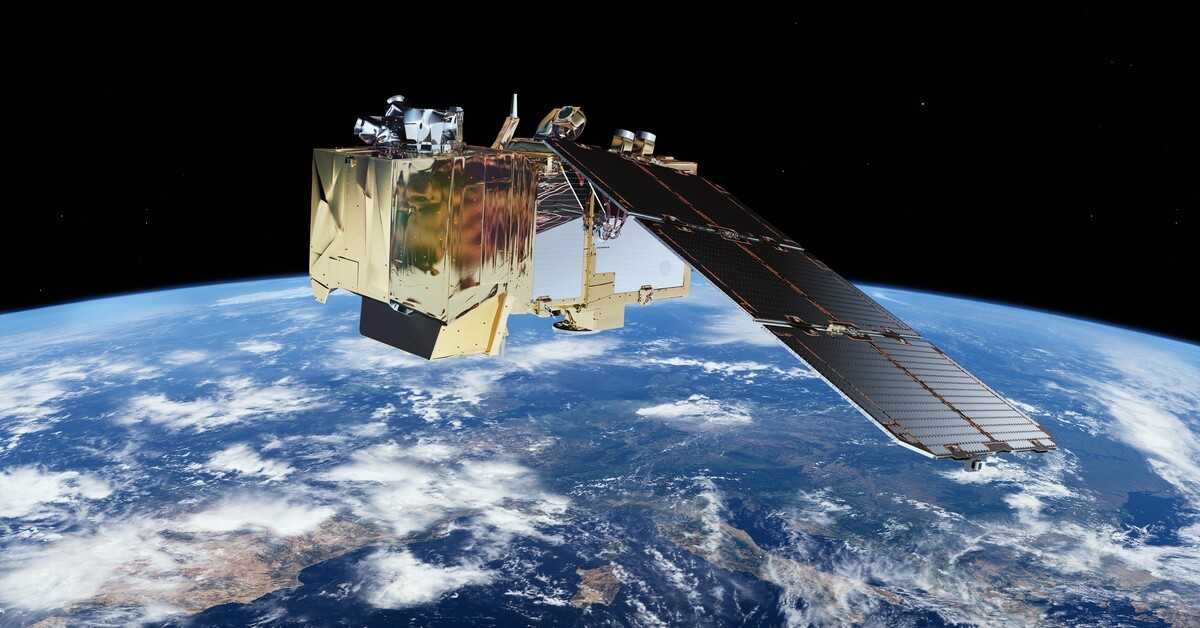

**Figure 1.** *Sentinel-2 satellite.  Source: Copernicus Data Space Ecosystem / European Space Agency (ESA).*

# 🛰️ Computer Vision for Archaeological Remote Sensing
### Detecting Cropmarks in Sentinel-2 Imagery
**Computer Vision in Archaeology Workshop**

**Author**: Filip Hájek

**Institution**: Centre for Multidisciplinary Research, Institute of Archaeology, CAS, Brno

**Date**: 17th of September 2026

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arubrno/atrium-school-ml-lessons/blob/main/4-thursday-satellite/cropmarks_filled.ipynb)

Runs unchanged in Google Colab, on the school JupyterHub, and in any local
Jupyter or IDE. The first code cell works out which of those you are in.

> **Before you change anything**, make it your own copy:
> - **Colab** — *File → Save a copy in Drive*. A notebook opened from GitHub
>   does not keep your edits.
> - **School JupyterHub** — copy this notebook from
>   `_atrium-school-ml-lessons/4-thursday-satellite/` into your own folder,
>   `/home/jovyan/<your name>/`, and open the copy.

This is the notebook with every cell filled in. The version with empty code
cells, for working along with the instructor, is
[`cropmarks.ipynb`](cropmarks.ipynb).



## About this notebook
This notebook introduces the basic principles of multispectral satellite image analysis and demonstrates how satellite imagery can be processed and classified using Python.

We will focus on:

multispectral imagery and spectral bands,
spectral signatures and spectral indices,
Sentinel-2 data,
raster processing with rasterio,
image processing,
supervised classification using Random Forest.

The practical exercises combine concepts from remote sensing, GIS, computer vision and machine learning.

# Introduction to Multispectral Satellite Image Analysis

## 1. From sunlight to satellite signal
Satellite imagery allows us to observe the Earth's surface repeatedly and over large areas.

Most optical remote-sensing satellites measure **solar radiation reflected from the Earth's surface**. Before reaching the ground, sunlight passes through the atmosphere, where part of the radiation is **absorbed or scattered**. At the surface, different materials absorb and reflect different amounts of energy at different wavelengths.

The reflected radiation then travels back through the atmosphere before reaching the satellite sensor, where it is recorded as a digital value.

Because the atmosphere influences the signal on both its downward and upward path, satellite data usually require **atmospheric correction**. This attempts to remove atmospheric effects and estimate the **surface reflectance** that would be measured directly at the Earth's surface.

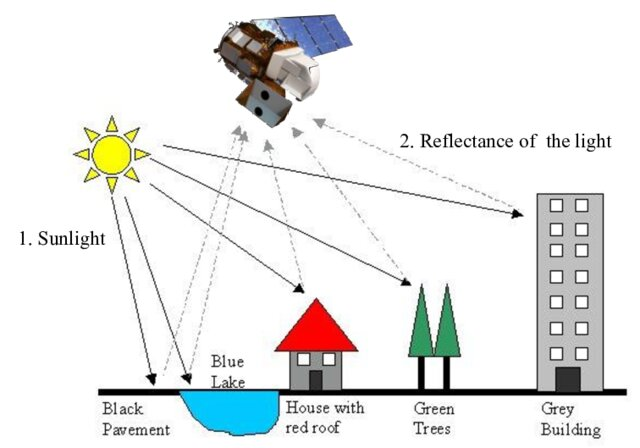

**Figure2:** *Spectral reflectance of satellite.Source: Mookdarsanit and Ketcham (2016), Fig.1*

## 2. From RGB images to multispectral data

A normal digital photograph typically contains three spectral channels:

* **Red**
* **Green**
* **Blue**

Together, these three channels produce an RGB image similar to what the human eye sees.

Multispectral satellite sensors measure additional wavelengths outside the visible spectrum.

> **RGB image:** three values for each pixel
> **Multispectral image:** several spectral measurements for each pixel

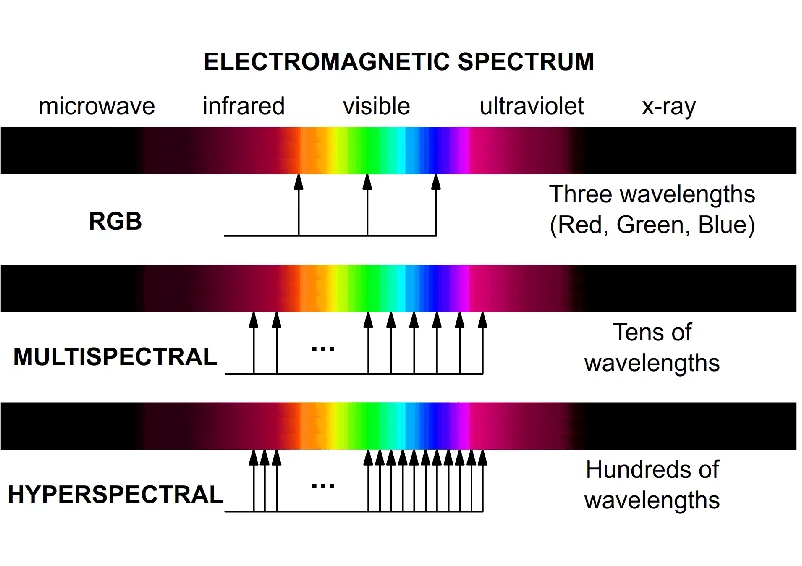

**Figure 3.** *Comparison of RGB, multispectral and hyperspectral imaging across the electromagnetic spectrum.  
Source: Zabalza (2015), Fig. 2.2.*

## 3. Spectral signatures

Different materials absorb and reflect electromagnetic radiation differently.

The pattern of reflectance across several wavelengths is called a **spectral signature**.

For example:

* healthy vegetation strongly reflects near-infrared radiation,
* water absorbs much of the near-infrared radiation,
* bare soil usually has a different reflectance pattern from vegetation,
* artificial materials may show different spectral responses depending on their composition.

Instead of asking:

> *What colour is this pixel?*

we can ask:

> *How does this surface reflect different wavelengths?*

This is one of the fundamental principles of multispectral remote sensing.

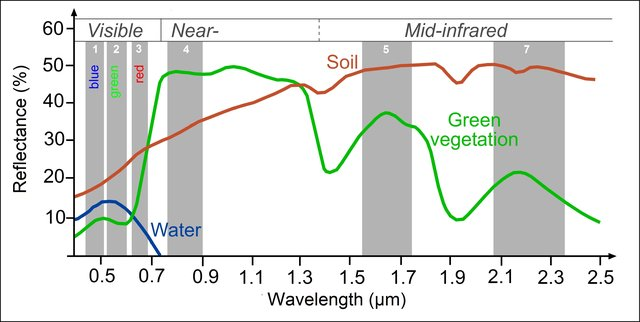

**Figure 4.** *Spectral signatures of soil, vegetation and water.  Source: Vermeulen (2020), Fig. 2.1.*

## 4. Spectral bands

Each Sentinel-2 band records reflected radiation within a particular part of the electromagnetic spectrum.

The Sentinel-2 MultiSpectral Instrument (MSI) records information in **13 spectral bands** ranging from visible light to the short-wave infrared (SWIR).

| Band | Spectral region | Central wavelength | Spatial resolution | Typical applications |
|---|---|---:|---:|---|
| **B1** | Coastal aerosol | ~443 nm | 60 m | Atmospheric correction, aerosol detection, coastal applications |
| **B2** | Blue | ~490 nm | 10 m | Water, visible imagery, atmospheric effects |
| **B3** | Green | ~560 nm | 10 m | Vegetation, water, visible imagery |
| **B4** | Red | ~665 nm | 10 m | Vegetation, soil, RGB imagery |
| **B5** | Red Edge 1 | ~705 nm | 20 m | Vegetation condition, chlorophyll |
| **B6** | Red Edge 2 | ~740 nm | 20 m | Vegetation condition, chlorophyll |
| **B7** | Red Edge 3 | ~783 nm | 20 m | Vegetation structure and condition |
| **B8** | Near Infrared (NIR) | ~842 nm | 10 m | Vegetation, biomass, water discrimination, NDVI |
| **B8A** | Narrow NIR / Red Edge 4 | ~865 nm | 20 m | Vegetation condition, red-edge analysis |
| **B9** | Water vapour | ~945 nm | 60 m | Atmospheric water-vapour detection and correction |
| **B10** | SWIR – Cirrus | ~1375 nm | 60 m | Cirrus-cloud detection and atmospheric correction |
| **B11** | SWIR 1 | ~1610 nm | 20 m | Moisture, vegetation stress, soil, snow/ice discrimination |
| **B12** | SWIR 2 | ~2190 nm | 20 m | Moisture, geology, burned areas, soil and mineral properties |

*Source: European Space Agency (2015), Sentinel-2 User Handbook.*

### Spatial resolution

Sentinel-2 bands have three different native spatial resolutions:

- **10 m:** B2, B3, B4, B8
- **20 m:** B5, B6, B7, B8A, B11, B12
- **60 m:** B1, B9, B10

The bands therefore differ not only in the wavelengths they record, but also in the level of spatial detail they capture.

By combining different bands we can create different representations of the landscape.

A **true colour image** usually uses:

**Red + Green + Blue**

while a **false colour image** may replace one of the visible channels with near-infrared information in order to highlight vegetation or other surface characteristics.

---

## 5. Spectral indices

Spectral indices combine information from two or more spectral bands in order to highlight a particular surface property.

One of the most commonly used indices is the **Normalized Difference Vegetation Index (NDVI)**:

$$
NDVI = \frac{NIR - Red}{NIR + Red}
$$

NDVI exploits the fact that healthy vegetation:

* absorbs much of the red light used for photosynthesis,
* strongly reflects near-infrared radiation.

As a result, healthy vegetation generally produces relatively high NDVI values.

The same principle can be used to create indices targeting other properties.

Examples include:

* **NDVI** → vegetation
* **NDWI** → water or surface moisture
* **NDBI** → built-up areas

Spectral indices therefore transform several spectral measurements into a variable that may be easier to interpret or classify.

---

## 6. From satellite imagery to computer vision

Satellite images can be analysed using methods ranging from simple image processing to advanced machine learning.

At the simplest level, **classical computer-vision and image-processing methods** can enhance or isolate particular patterns using techniques such as:

- thresholding,
- filtering,
- edge or ridge detection,
- morphological operations.

More complex patterns can be identified using **machine-learning methods**. These algorithms learn from examples and use spectral, spatial or derived features to classify pixels or objects. Common approaches include methods such as Random Forest or Support Vector Machines.

More recently, **deep-learning methods** based on neural networks can learn relevant features directly from imagery. Convolutional Neural Networks (CNNs) and segmentation networks such as U-Net can be used for tasks such as object detection, image classification and semantic segmentation.

These approaches are not mutually exclusive. A remote-sensing workflow may combine several of them:

**Satellite data → spectral processing → image enhancement → feature extraction → machine learning → spatial interpretation**

In this notebook, we will follow a hybrid approach combining **spectral analysis, classical computer vision and Random Forest classification** to identify archaeological cropmark candidates.

## 8. Archaeological cropmarks

**Cropmarks** are differences in crop growth caused by buried archaeological features. Ditches may retain more moisture and support stronger vegetation growth, while walls or compacted surfaces can restrict roots and produce weaker growth.

These differences can appear as patterns in colour, vegetation density or spectral response, making buried structures visible in aerial and satellite imagery.

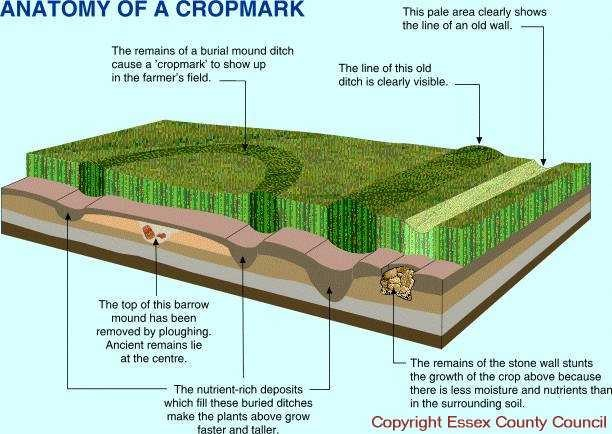

**Figure 5.** *Anatomy of a cropmark. Source: Shropshire Council (2018).*

# 🛰️ Case Study: Cornești-Iarcuri

In this exercise, we will work with **Sentinel-2 Level-2A multispectral imagery** covering the archaeological site of **Cornești-Iarcuri, Romania**.

**Location:** 45.932–45.934° N, 21.236–21.238° E  
**Acquisition date:** **7 April 2026**  
**Data:** Sentinel-2 Level-2A

Cornești-Iarcuri is a monumental **Bronze Age fortification consisting of four concentric earthen ramparts**, enclosing more than 17 km² and representing the largest known Bronze Age fortification in Europe.

The Sentinel-2 image contains a visible **archaeological cropmark associated with the fortification**, which we will use as the target for image segmentation.

Our objective is to use multispectral image processing and computer-vision techniques to:

- enhance the cropmark signal,
- distinguish it from surrounding vegetation and field variability,
- and ultimately **segment the cropmark from the satellite image**.

For the main analysis, we will use the four Sentinel-2 bands available at **10 m spatial resolution**:

- **B2** — Blue
- **B3** — Green
- **B4** — Red
- **B8** — Near Infrared

*Source for archaeological site description: Wikipedia contributors, “Cornești-Iarcuri”.*

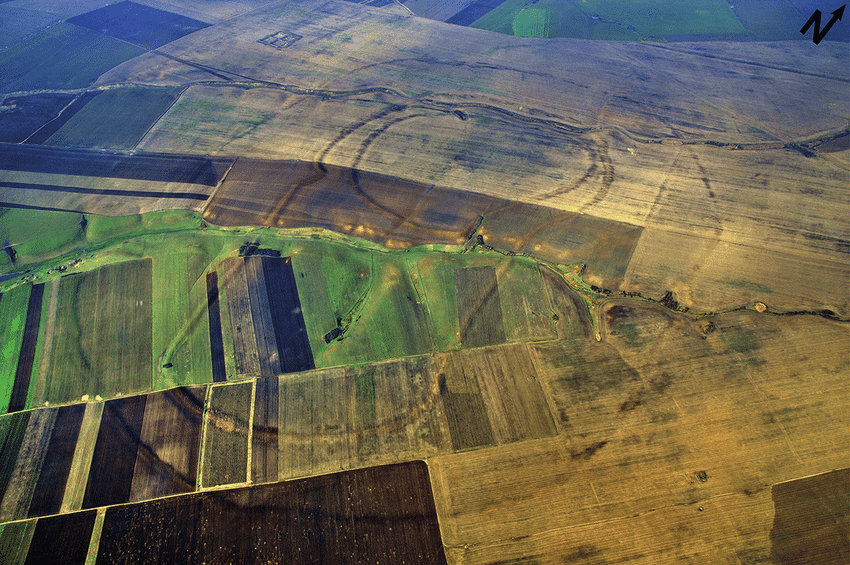

**Figure 6.** *Aerial view of the Bronze Age fortification at Cornești-Iarcuri, Romania.
Source: Nykamp et al. (2017), via Wikimedia Commons, CC BY-SA 3.0.*

## Python tools used in this notebook

This workflow combines several specialised Python libraries.

### Raster and numerical processing

- **NumPy** — numerical operations on raster arrays.
- **Rasterio** — reading, writing and georeferencing raster data such as GeoTIFFs.
- **OpenCV** — general image-processing operations; here it is used for Gaussian filtering.

### Computer vision

- **scikit-image** — image-analysis algorithms not included in basic numerical libraries. Here we use the Frangi filter for enhancement of line-like structures.

### Machine learning

- **scikit-learn** — machine-learning algorithms and evaluation tools. Here we use a Random Forest classifier.

### Geospatial vector data

- **GeoPandas** — reading, manipulating and exporting spatial vector data.
- **Shapely** — geometry objects and raster-to-vector conversion support.

### Visualisation

- **Matplotlib** — visualisation of raster data, intermediate processing results and model outputs.

No single library performs the complete workflow. The analysis moves between remote sensing, image processing, machine learning and GIS.

## Setup

Run the next cell and read what it prints. It finds the course repository
(cloning it first if you are in Colab) and installs only the packages that are
missing: here the geospatial ones, rasterio and GeoPandas, plus scikit-image
and scikit-learn.

Nothing below this cell knows or cares which platform you chose.

In [ ]:
# --- ATRIUM bootstrap: identical in every notebook of this school ------------
# Colab starts with none of this repository, so this cell has to be able to
# fetch it before it can import anything of ours. Everything else lives in
# atrium_bootstrap.py at the repository root.
import pathlib, subprocess, sys

REPO = "https://github.com/arubrno/atrium-school-ml-lessons.git"
HUB_REPO = pathlib.Path.home() / "_atrium-school-ml-lessons"   # the shared copy on the school hub

here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents, HUB_REPO]
             if (p / "atrium_bootstrap.py").exists()), None)
if root is None:
    root = pathlib.Path("atrium-school-ml-lessons").resolve()
    if not (root / "atrium_bootstrap.py").exists():
        print("fetching the course repository ...")
        subprocess.run(["git", "clone", "--depth", "1", REPO, str(root)], check=True)

sys.path.insert(0, str(root))
from atrium_bootstrap import setup

# drive=True on Colab keeps the model weights in your Google Drive between sessions.
setup("opencv-python-headless", "pandas", "rasterio", "geopandas", "scikit-image", "scikit-learn");

## Import Python libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import cv2

from rasterio.plot import plotting_extent

## Load the Sentinel-2 bands

The four Sentinel-2 bands were previously downloaded as georeferenced GeoTIFF files.
They come with the course, together with the training points you will use later.
`get_dataset("satellite")` returns the folder that holds them:

- `sentinel2/` — the four bands, B2, B3, B4 and B8,
- `training_samples/` — the cropmark and non-cropmark training points,
- `round2/` — the hard negatives for the second Random Forest,
- `gis/` — the cropmark polygons after review in GIS.

Because B2, B3, B4 and B8 have a native spatial resolution of 10 m, they can be analysed together without resampling if their grids are already aligned.

In [ ]:
from atrium_data import get_dataset

data = get_dataset("satellite")

# Everything this notebook writes goes to an "outputs" folder next to it.
output_dir = pathlib.Path("outputs")
output_dir.mkdir(exist_ok=True)

print("data   :", data)
print("outputs:", output_dir.resolve())

In [ ]:
sentinel2 = data / "sentinel2"

b2_path = sentinel2 / "2026-04-07-00_00_2026-04-07-23_59_Sentinel-2_L2A_B02_(Raw).tiff"
b3_path = sentinel2 / "2026-04-07-00_00_2026-04-07-23_59_Sentinel-2_L2A_B03_(Raw).tiff"
b4_path = sentinel2 / "2026-04-07-00_00_2026-04-07-23_59_Sentinel-2_L2A_B04_(Raw).tiff"
b8_path = sentinel2 / "2026-04-07-00_00_2026-04-07-23_59_Sentinel-2_L2A_B08_(Raw).tiff"

## Read the raster data

`rasterio` reads both the pixel values and the geospatial metadata of a raster.

For every band we retain:

- pixel values,
- CRS,
- affine transformation,
- raster dimensions,
- NoData information.

In [ ]:
def read_band(path):

    with rasterio.open(path) as src:

        band = src.read(1).astype("float32") # Read pixel values from band 1 as a NumPy array

        profile = src.profile.copy()  # Save metadata such as size, data type and CRS
        transform = src.transform  # Pixel-to-map coordinate transformation
        crs = src.crs  # Coordinate reference system of the raster
        nodata = src.nodata  # Value used to represent missing pixels

    if nodata is not None:  # If a NoData value exists
        band[band == nodata] = np.nan  # Convert NoData to NaN so calculations can ignore it

    return band, profile, transform, crs  # Return both raster values and spatial metadata

In [ ]:
# Load B2 and keep both pixel values and geospatial metadata
b2, profile, transform, crs = read_band(b2_path)

# Load the remaining bands
# "_" means that the returned metadata are not needed here
b3, _, _, _ = read_band(b3_path)
b4, _, _, _ = read_band(b4_path)
b8, _, _, _ = read_band(b8_path)

print("CRS:", crs) # Coordinate reference system
print("Raster shape:", b2.shape) # Number of rows and columns
print(
    "Pixel size:",
    transform.a,          # Pixel width
    abs(transform.e)      # Pixel height
)

## Check raster alignment

Multispectral analysis assumes that corresponding pixels in all bands represent the same ground location.

Therefore, all bands must have identical raster dimensions.

In [ ]:
print("B2:", b2.shape)
print("B3:", b3.shape)
print("B4:", b4.shape)
print("B8:", b8.shape)

assert b2.shape == b3.shape == b4.shape == b8.shape, \
    "The raster bands do not have the same dimensions."

print("All bands have matching dimensions.")

## Visualise individual spectral bands

Before calculating indices or applying computer vision, it is useful to inspect the original spectral information.

Different wavelengths respond differently to vegetation, soil and moisture conditions.

In [ ]:
fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

bands = [b2, b3, b4, b8]
titles = [
    "B2 - Blue",
    "B3 - Green",
    "B4 - Red",
    "B8 - NIR"
]

# zip() combines several sequences element by element.
#
# Here we combine:
#   axes  -> the four plotting areas
#   bands -> the four raster bands
#   titles -> the four band names
#
# Conceptually, zip() creates:
#
# (axes[0], b2, "B2 - Blue")
# (axes[1], b3, "B3 - Green")
# (axes[2], b4, "B4 - Red")
# (axes[3], b8, "B8 - NIR")
#
# The for-loop processes one of these groups at a time.

for ax, band, title in zip(
    axes,
    bands,
    titles
):
    ax.imshow(
        band,
        cmap="gray"
    )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Create an RGB composite

A true-colour image combines:

- Red = B4
- Green = B3
- Blue = B2

Satellite reflectance values need to be stretched for display.

A percentile stretch reduces the influence of extreme values and improves visual contrast.

In [ ]:
def percentile_stretch(
    band,        # Input raster band as a NumPy array
    low=2,       # Lower percentile used for contrast stretching
    high=98      # Upper percentile used for contrast stretching
):

    # Keep only valid, finite pixel values above zero
    # This avoids NaN, Inf and background / NoData-like values
    valid = band[
        np.isfinite(band) &
        (band > 0)
    ]

    # Find the pixel value corresponding to the lower percentile
    # Example: with low=2, 2% of valid pixels have lower values
    p_low = np.percentile(
        valid,
        low
    )

    # Find the pixel value corresponding to the upper percentile
    # Example: with high=98, 98% of valid pixels have lower values
    p_high = np.percentile(
        valid,
        high
    )

    # Rescale pixel values so that:
    # p_low  -> 0
    # p_high -> 1
    stretched = (
        band - p_low
    ) / (
        p_high - p_low + 1e-10
    )

    # Clip values outside the 0-1 range
    # Pixels below p_low become 0
    # Pixels above p_high become 1
    return np.clip(
        stretched,
        0,
        1
    )

Percentile stretching does not alter the analytical data; it is used only to improve contrast for visualization.

In [ ]:
# Print basic summary statistics for each spectral band.
# These values help us inspect the range and distribution of pixel values
# before further processing and visualisation.

for name, band in [
    ("B2", b2),
    ("B3", b3),
    ("B4", b4),
    ("B8", b8)
]:
    print(
        name,
        "min =", np.nanmin(band),
        "median =", np.nanmedian(band),
        "p98 =", np.nanpercentile(band, 98),
        "max =", np.nanmax(band)
    )

### RGB percentile stretch

For a single spectral band, contrast stretching can be calculated independently.

For a true-colour RGB image, however, stretching each channel separately can distort the colour balance.

We therefore combine the red, green and blue channels first and calculate **one common percentile range** for all three channels.

The same stretch is then applied to R, G and B, helping to preserve their relative brightness and produce a more natural-looking colour composite.

In [ ]:
def rgb_percentile_stretch(
    red,         # Red channel
    green,       # Green channel
    blue,        # Blue channel
    low=2,       # Lower percentile for contrast stretching
    high=98      # Upper percentile for contrast stretching
):

    # Stack the three 2D bands into one 3D RGB array:
    # (rows, columns, 3 channels)
    rgb_raw = np.dstack([
        red,
        green,
        blue
    ]).astype("float32")

    # Select valid values from all three channels together.
    # This creates one common pool of pixel values for RGB.
    valid = rgb_raw[
        np.isfinite(rgb_raw) &
        (rgb_raw > 0)
    ]

    # Calculate one common lower percentile
    # for all three RGB channels
    p_low = np.percentile(
        valid,
        low
    )

    # Calculate one common upper percentile
    # for all three RGB channels
    p_high = np.percentile(
        valid,
        high
    )

    # Apply the same contrast stretch to all three channels.
    # p_low  -> 0
    # p_high -> 1
    #
    # Using one common stretch helps preserve the relative
    # brightness and colour balance between R, G and B.
    rgb = (
        rgb_raw - p_low
    ) / (
        p_high - p_low + 1e-10 # Add a tiny value to avoid division by zero
    )

    # Limit values to the display range 0-1
    rgb = np.clip(
        rgb,
        0,
        1
    )

    return rgb

In [ ]:
rgb = rgb_percentile_stretch(
    b4,   # Red
    b3,   # Green
    b2    # Blue
)

plt.figure(figsize=(10, 10))

plt.imshow(rgb)

plt.title(
    "Sentinel-2 RGB — 7 April 2026"
)

plt.axis("off")

plt.show()

## From stored values to surface reflectance

Sentinel-2 Level-2A data represent atmospherically corrected **surface reflectance**.

In the downloaded 16-bit raster files, reflectance is stored using a scale factor of 10,000. For example:

\[
2500 \rightarrow 0.25
\]

We therefore divide the raster values by 10,000 before further analysis.

This conversion does not change the information contained in the image; it only converts the stored integer values into physically interpretable reflectance values.

In [ ]:
b2 = b2 / 10000.0
b3 = b3 / 10000.0
b4 = b4 / 10000.0
b8 = b8 / 10000.0

## False-colour vegetation composite

Near-infrared reflectance is particularly sensitive to vegetation structure and condition.

A false-colour composite using NIR, Red and Green can reveal vegetation differences that are less obvious in true colour.

In [ ]:
false_colour_raw = np.dstack([
    b8,
    b4,
    b3
]).astype("float32")

# Select valid pixel values from all three channels together.
# NaN, Inf and non-positive values are excluded from the stretch calculation.
valid = false_colour_raw[
    np.isfinite(false_colour_raw) &
    (false_colour_raw > 0)
]

# Calculate one common 2nd and 98th percentile
# for all three display channels.
p_low, p_high = np.percentile(
    valid,
    [2, 98]
)

# Stretch all channels using the same percentile range.
# p_low  -> 0
# p_high -> 1
false_colour = (
    false_colour_raw - p_low
) / (
    p_high - p_low + 1e-10
)

# Limit all display values to the range 0-1.
false_colour = np.clip(
    false_colour,
    0,
    1
)


plt.figure(figsize=(10, 10))

plt.imshow(false_colour)

plt.title(
    "False colour composite — B8/B4/B3"
)

plt.axis("off")

plt.show()

## Normalized Difference Vegetation Index

NDVI measures the contrast between near-infrared and red reflectance:

\[
NDVI = {NIR - Red} / {NIR + Red}
\]

Healthy vegetation generally reflects strongly in the near-infrared and absorbs red light.

Archaeological remains below the surface can influence soil depth, moisture availability and plant development. This can create local differences in vegetation response above buried structures.

In [ ]:
# Calculate NDVI


# Calculate the denominator of the NDVI equation:
# NIR + Red = B8 + B4
denominator = b8 + b4

# Create an empty NDVI raster with the same dimensions as B8.
# All pixels are initially filled with NaN.
ndvi = np.full(
    b8.shape,
    np.nan,
    dtype="float32"
)

# Create a boolean mask identifying pixels where NDVI can be calculated safely.
#
# A pixel is valid only if:
# - B8 contains a finite value,
# - B4 contains a finite value,
# - the denominator is not zero.
valid = (
    np.isfinite(b8) &
    np.isfinite(b4) &
    (denominator != 0)
)

# Calculate NDVI only for valid pixels.
# Invalid pixels remain NaN.
ndvi[valid] = (
    b8[valid] - b4[valid]
) / denominator[valid]

# Print basic summary statistics of the resulting NDVI raster.
# np.nan... functions ignore pixels containing NaN.
print("NDVI min:", np.nanmin(ndvi))
print("NDVI max:", np.nanmax(ndvi))
print("NDVI mean:", np.nanmean(ndvi))

In [ ]:
# Visualization of NDVI

plt.figure(figsize=(10, 10))

im = plt.imshow(
    ndvi,
    cmap="RdYlGn",
    vmin=0,
    vmax=1
)

plt.colorbar(
    im,
    label="NDVI"
)

plt.title(
    "NDVI — 7 April 2026"
)

plt.axis("off")

plt.show()

## RGB and NDVI comparison

The archaeological cropmark does not necessarily have the same absolute spectral expression across different fields.

It may appear:

- less vegetated than its surroundings in one field,
- more vegetated in another field,
- or as a combination of contrasting edges and centre.

Therefore, absolute NDVI alone may not be sufficient for detecting the complete archaeological structure.

A useful alternative is to compare each pixel with its **local surroundings**.

In [ ]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 7)
)

axes[0].imshow(rgb)
axes[0].set_title("RGB")
axes[0].axis("off")


im = axes[1].imshow(
    ndvi,
    cmap="RdYlGn",
    vmin=0,
    vmax=1
)

axes[1].set_title("NDVI")
axes[1].axis("off")

plt.colorbar(
    im,
    ax=axes[1],
    fraction=0.046,
    pad=0.04
)

plt.tight_layout()
plt.show()

# Local background removal

Different agricultural fields may have very different overall vegetation conditions.

Instead of asking:

> What is the absolute NDVI value of this pixel?

we can ask:

> How different is this pixel from the vegetation immediately surrounding it?

A Gaussian filter is used to estimate the broad local vegetation background.

The local anomaly is then calculated as:

\[
A = NDVI - NDVI_{background}
\]

where:

- positive values indicate locally higher NDVI,
- negative values indicate locally lower NDVI,
- values close to zero indicate little difference from the local surroundings.

In [ ]:
# Identify pixels containing valid finite NDVI values.
# np.isfinite() returns True for normal numbers
# and False for NaN or infinite values.
valid_mask = np.isfinite(ndvi)

# Replace invalid NDVI pixels temporarily with 0.
#
# np.where(condition, value_if_true, value_if_false)
#
# Valid pixel   -> keep the original NDVI value
# Invalid pixel -> replace it with 0
ndvi_values = np.where(
    valid_mask,
    ndvi,
    0
).astype("float32")

# Convert the boolean mask into numerical weights:
#
# True  -> 1.0
# False -> 0.0
#
# These weights will later allow the Gaussian filter
# to ignore invalid pixels when calculating local background.
weights = valid_mask.astype(
    "float32"
)

In [ ]:
# Standard deviation of the Gaussian filter; controls the spatial scale of smoothing
sigma = 3

# Apply Gaussian smoothing to the NDVI values.
# This creates a locally averaged, smoother version of the NDVI image,
# which represents the broad vegetation background.
blurred_values = cv2.GaussianBlur(
    ndvi_values,   # Input NDVI raster with invalid pixels temporarily replaced by 0
    (0, 0),        # Kernel size is chosen automatically from sigma
    sigmaX=sigma,  # Horizontal smoothing strength
    sigmaY=sigma   # Vertical smoothing strength
)

# Apply the same Gaussian smoothing to the weights raster.
# This tells us how much valid data contributed to each local average.
blurred_weights = cv2.GaussianBlur(
    weights,       # Weight raster: valid pixels = 1, invalid pixels = 0
    (0, 0),        # Kernel size is again determined automatically
    sigmaX=sigma,  # Horizontal smoothing strength
    sigmaY=sigma   # Vertical smoothing strength
)

In [ ]:
# Create an empty raster for the local NDVI background.
#
# np.full(shape, value, dtype) creates a new NumPy array
# with a given shape and fills every cell with the same value.

local_background = np.full(
    ndvi.shape, # shape = ndvi.shape -> same dimensions as the NDVI raster
    np.nan, # value = np.nan  -> all pixels start as missing / undefined
    dtype="float32" # dtype = float32 -> floating-point raster
)

# Identify pixels where the smoothed weights are greater than zero.
good = blurred_weights > 0

# Calculate the local background only where valid data exist.
local_background[good] = (
    blurred_values[good] /
    blurred_weights[good]
)

## Local NDVI background

The smoothed raster represents broad vegetation variation.

Large-scale differences between fields are retained, while narrow local variations are suppressed.

This background can then be subtracted from the original NDVI to enhance smaller vegetation anomalies.

In [ ]:
#Visualization (Original NDVI and Local NDVI Background)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 7)
)

axes[0].imshow(
    ndvi,
    cmap="RdYlGn",
    vmin=0,
    vmax=1
)

axes[0].set_title(
    "Original NDVI"
)

axes[0].axis("off")


axes[1].imshow(
    local_background,
    cmap="RdYlGn",
    vmin=0,
    vmax=1
)

axes[1].set_title(
    "Local NDVI background"
)

axes[1].axis("off")


plt.tight_layout()
plt.show()

In [ ]:
# Subtract the smoothed local background from the original NDVI.
# This highlights pixels that differ from their immediate surroundings.
local_anomaly = (
    ndvi - local_background
)

# Restore invalid pixels as NaN.
# "~" means logical NOT:
# valid_mask == True  -> remains unchanged
# valid_mask == False -> set to NaN
local_anomaly[
    ~valid_mask
] = np.nan

local_anomaly > 0 → the pixel has a higher NDVI than its local surroundings

local_anomaly < 0 → the pixel has a lower NDVI than its local surroundings

"~" means logical NOT

In [ ]:
# Calculate the 98th percentile of the absolute anomaly values.
# Using the 98th percentile prevents a few extreme outliers
# from controlling the entire colour scale.
limit = np.nanpercentile(
    np.abs(local_anomaly),
    98
)

plt.figure(figsize=(10, 10))

# Display the local NDVI anomaly.
#
# RdBu_r is a diverging colour map suitable for values
# that vary around a meaningful centre, here 0.
#
# vmin and vmax are set symmetrically:
# -limit -> strongest displayed negative anomaly
# +limit -> strongest displayed positive anomaly
#
# This ensures that equal positive and negative deviations
# are shown with equal visual intensity.
im = plt.imshow(
    local_anomaly,
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit
)

plt.colorbar(
    im,
    label="NDVI difference from local background"
)

plt.title(
    "Local NDVI anomaly"
)

plt.axis("off")

plt.show()

## Positive and negative vegetation anomalies

Because the archaeological cropmark has different spectral expressions across different fields, both directions of vegetation change are retained.

### Positive anomaly

\[
NDVI > local\ background
\]

The vegetation is locally stronger than its surroundings.

### Negative anomaly

\[
NDVI < local\ background
\]

The vegetation is locally weaker than its surroundings.

We also calculate the absolute anomaly to represent the strength of local change irrespective of direction.

In [ ]:
# Keep only positive local anomalies.
#
# np.clip(array, min, max) limits values to a specified range.
#
# Here:
# - negative values become 0
# - positive values remain unchanged
# - no upper limit is applied because max=None

positive_anomaly = np.clip(
    local_anomaly,
    0,
    None
)

# Keep only negative local anomalies.
#
# First, multiply local_anomaly by -1:
# negative anomalies become positive values,
# while positive anomalies become negative values.
#
# np.clip() then removes the negative values,
# leaving only the magnitude of originally negative anomalies.
negative_anomaly = np.clip(
    -local_anomaly,
    0,
    None
)

# Calculate the absolute magnitude of the local anomaly.
#
# np.abs() removes the sign:
# +0.10 -> 0.10
# -0.10 -> 0.10
#
# This represents the strength of the local difference
# regardless of whether NDVI is higher or lower than the surroundings.
absolute_anomaly = np.abs(
    local_anomaly
)

In [ ]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 6)
)

# Signed anomaly
im1 = axes[0].imshow(
    local_anomaly,
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit
)

axes[0].set_title( # Set the title of the first subplot
    "Signed local anomaly"
)

axes[0].axis("off")


# Negative anomaly
im2 = axes[1].imshow(
    negative_anomaly,
    cmap="inferno",
    vmin=0,  # Anomaly magnitude starts at zero
    vmax=limit   # Upper display limit based on the 98th percentile
)

axes[1].set_title( # Set the title of the second subplot
    "Negative NDVI anomaly"
)

axes[1].axis("off")


# Positive anomaly
im3 = axes[2].imshow(
    positive_anomaly,
    cmap="inferno",
    vmin=0,  # Anomaly magnitude starts at zero
    vmax=limit   # Upper display limit based on the 98th percentile
)

axes[2].set_title( # Set the title of the third subplot
    "Positive NDVI anomaly"
)

axes[2].axis("off")


plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 10))

im = plt.imshow(
    absolute_anomaly,
    cmap="inferno",
    vmin=0,
    vmax=limit
)

plt.colorbar(
    im,
    label="Absolute NDVI difference"
)

plt.title(
    "Absolute local NDVI anomaly"
)

plt.axis("off")

plt.show()

In [ ]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

axes[0].imshow(rgb)
axes[0].set_title("RGB")
axes[0].axis("off")


axes[1].imshow(
    ndvi,
    cmap="RdYlGn",
    vmin=0,
    vmax=1
)

axes[1].set_title("NDVI")
axes[1].axis("off")


axes[2].imshow(
    absolute_anomaly,
    cmap="inferno",
    vmin=0,
    vmax=limit
)

axes[2].set_title(
    "Local NDVI anomaly"
)

axes[2].axis("off")


plt.tight_layout()
plt.show()

# Line / ridge enhancement

Local background removal enhances vegetation anomalies, but it also responds strongly to field boundaries, roads and other abrupt transitions.

The archaeological cropmark, however, forms a relatively narrow and continuous curvilinear structure.

To enhance such line-like features, we apply a **Frangi ridge filter**.

The filter analyses local image curvature at several spatial scales and produces a continuous response:

- high values = strong line / ridge-like structure,
- low values = weak or non-linear structure.

Positive and negative NDVI anomalies are processed separately because the cropmark can be either greener or less green than its surroundings depending on the field.

In [ ]:
from skimage.filters import frangi

In [ ]:
def normalize_anomaly(
    anomaly,          # Input anomaly raster
    percentile=99     # Upper percentile used for normalization
):

    # Select only valid positive anomaly values.
    values = anomaly[
        np.isfinite(anomaly) &
        (anomaly > 0)
    ]

    # Calculate the selected upper percentile.
    upper = np.percentile(
        values,
        percentile
    )
    # Normalize the anomaly values by dividing them by the upper percentile.
    normalized = anomaly / upper

    # Restrict the normalized values to the range 0-1.
    #
    # Values below 0 become 0.
    # Values above 1 become 1.
    normalized = np.clip(
        normalized,
        0,
        1
    )

    # Replace any remaining NaN or infinite values with 0.
    normalized[~np.isfinite(normalized)] = 0

    return normalized

In [ ]:
# Normalize positive anomalies to the 0-1 range
positive_norm = normalize_anomaly(
    positive_anomaly
)

# Normalize negative anomalies to the 0-1 range
negative_norm = normalize_anomaly(
    negative_anomaly
)

In [ ]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 7)
)

axes[0].imshow(
    positive_norm,
    cmap="inferno"
)

axes[0].set_title(
    "Positive local anomaly"
)

axes[0].axis("off")


axes[1].imshow(
    negative_norm,
    cmap="inferno"
)

axes[1].set_title(
    "Negative local anomaly"
)

axes[1].axis("off")


plt.tight_layout()
plt.show()

In [ ]:
# Define the range of spatial scales for the Frangi filter.
# Here, the filter will analyse line-like structures at sigma = 1, 2 and 3 pixels.
sigmas = range(1, 4)


# Apply the Frangi ridge filter to the normalized positive anomaly raster.
#
# The Frangi filter enhances narrow line- or ridge-like structures.
# In this case, it highlights curvilinear positive vegetation anomalies
# that may correspond to parts of the archaeological cropmark.
#
# black_ridges=False means that the features of interest are expected
# to be brighter than the background
ridge_positive = frangi(
    positive_norm,
    sigmas=sigmas,
    black_ridges=False
)

# Apply the same Frangi ridge filter to the normalized negative anomaly raster.
#
# This highlights line-like structures represented by negative vegetation anomalies,
# because some parts of the cropmark may appear as locally weaker vegetation
# rather than stronger vegetation.
ridge_negative = frangi(
    negative_norm,
    sigmas=sigmas,
    black_ridges=False
)

In [ ]:
# Remove NoData areas

ridge_positive[~valid_mask] = np.nan
ridge_negative[~valid_mask] = np.nan

## Positive and negative ridge response

The two anomaly directions are analysed independently.

This is useful because different parts of the same archaeological feature may produce opposite vegetation responses in different fields.

In [ ]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 7)
)

im1 = axes[0].imshow(
    ridge_positive,
    cmap="inferno"
)

axes[0].set_title(
    "Ridge response — positive anomaly"
)

axes[0].axis("off")


im2 = axes[1].imshow(
    ridge_negative,
    cmap="inferno"
)

axes[1].set_title(
    "Ridge response — negative anomaly"
)

axes[1].axis("off")


plt.tight_layout()
plt.show()

In [ ]:
# Combine the positive and negative ridge responses.
#
# np.fmax(a, b) compares the two arrays element by element
# and keeps the larger value at each pixel.
#
# This means that for every location, we retain the stronger
# Frangi response, regardless of whether it came from
# the positive or the negative anomaly image.
ridge_combined = np.fmax(
    ridge_positive,
    ridge_negative
)

ridge_combined[
    ~valid_mask
] = np.nan

In [ ]:
# Visualization of Combined line / ridge enhancement

plt.figure(
    figsize=(10, 10)
)

im = plt.imshow(
    ridge_combined,
    cmap="inferno"
)

plt.colorbar(
    im,
    label="Frangi ridge response"
)

plt.title(
    "Combined line / ridge enhancement"
)

plt.axis("off")

plt.show()

In [ ]:
# Comparison of Original RGB and Combined line / ridge enhancement

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 7)
)

axes[0].imshow(rgb)

axes[0].set_title(
    "RGB"
)

axes[0].axis("off")


axes[1].imshow(
    ridge_combined,
    cmap="inferno"
)

axes[1].set_title(
    "Frangi ridge response"
)

axes[1].axis("off")


plt.tight_layout()
plt.show()

In [ ]:
# Calculate the 99th percentile of the combined Frangi response.
ridge_limit = np.nanpercentile(
    ridge_combined,
    99
)

# Normalize the combined ridge response to the range 0-1.
ridge_display = np.clip(
    ridge_combined / ridge_limit,
    0,
    1
)

In [ ]:
# Calculate the 90th percentile of the combined Frangi ridge response.
ridge_vmax = np.nanpercentile(
    ridge_combined,
    90
)

plt.figure(figsize=(7, 7))

plt.imshow(
    ridge_combined,
    cmap="inferno",
    vmin=0,
    vmax=ridge_vmax
)

plt.title(
    "Frangi ridge response — clipped at 90th percentile"
)

plt.axis("off")
plt.show()

# Hybrid CV + Random Forest classification

Individual computer-vision operations enhance different properties of the archaeological feature, but none of them is sufficiently specific on its own.

For example:

- spectral bands describe reflectance,
- NDVI describes vegetation response,
- local anomaly describes contrast with the immediate surroundings,
- Frangi response describes line-like spatial structure.

These different sources of information can be combined into a single feature stack and used to train a supervised Random Forest classifier.

The objective is not to classify pixels using only their colour or only their geometry, but to combine:

**spectral + vegetation + local-context + spatial-shape information.**

In [ ]:
import pandas as pd
import geopandas as gpd

from rasterio.transform import rowcol

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## Load the training points

The training points were drawn by hand in GIS and saved as shapefiles.

In [ ]:
cropmark_path = data / "training_samples" / "cropmark.shp"
non_cropmark_path = data / "training_samples" / "non_cropmark.shp"

In [ ]:
# Open shapefiles with Geopandas

cropmark_points = gpd.read_file(
    cropmark_path
)

non_cropmark_points = gpd.read_file(
    non_cropmark_path
)

## Training labels

Random Forest is a **supervised machine-learning algorithm**.

Unlike the previous image-processing steps, it cannot determine by itself what represents an archaeological cropmark. It requires labelled examples.

Two classes are used:

- **Class 0 — cropmark**
- **Class 1 — non-cropmark**

Training points were manually placed on locations where the interpretation is reasonably clear.

The samples deliberately include cropmark expressions across different agricultural fields because the same archaeological feature can have different spectral appearances depending on vegetation conditions.

Non-cropmark samples include both ordinary background and visually similar structures such as field boundaries, vegetation patches and agricultural lines.

Each point is converted to the corresponding Sentinel-2 pixel and the predictor values at that pixel are extracted.

In [ ]:
# Add class labels to the training data.
cropmark_points["class"] = 0
non_cropmark_points["class"] = 1

In [ ]:
# Combine cropmark and non-cropmark training points
# into one single GeoDataFrame.

training_points = gpd.GeoDataFrame(

    # pd.concat() joins multiple tables together.
    # Here, the two GeoDataFrames are stacked row by row.
    pd.concat(
        [
            cropmark_points,
            non_cropmark_points
        ],
        # Create a new continuous row index:
        # 0, 1, 2, 3, ...
        ignore_index=True
    ),
    # Keep the coordinate reference system
    # from the cropmark training points.
    crs=cropmark_points.crs
)

In [ ]:
# Reproject all training points to the same CRS
# as the raster data
training_points = training_points.to_crs(
    crs
)

# Print the CRS to verify that the training points
# and raster use the same coordinate system.
print(
    "Training CRS:",
    training_points.crs
)

# Count how many training points belong to each class.
# value_counts() returns the number of occurrences
# of each unique value in the "class" column.
print(
    training_points["class"].value_counts()
)

In [ ]:
fig, ax = plt.subplots(
    figsize=(10, 10)
)

ax.imshow(rgb)

# Loop through the two training classes:
# 0 = Cropmark
# 1 = Non-cropmark
for class_value, label in [
    (0, "Cropmark"),
    (1, "Non-cropmark")
]:

    # Select only the training points belonging
    # to the current class.
    subset = training_points[
        training_points["class"] == class_value
    ]

    # Empty lists for raster row and column positions.
    rows, cols = [], []

    # Loop through all point geometries in the selected class.
    for geom in subset.geometry:

        # Convert map coordinates (x, y)
        # to raster coordinates (row, column).
        row, col = rowcol(
            transform,
            geom.x,
            geom.y
        )

        # Store the raster position of each point.
        rows.append(row)
        cols.append(col)

    # Plot the training points on top of the RGB image.
    #
    # scatter() expects x first and y second,
    # therefore columns are used as x
    # and rows as y.
    ax.scatter(
        cols,
        rows,
        s=20,
        label=label
    )

# Add a legend showing the two classes.
ax.legend()

ax.set_title(
    "Training samples"
)

ax.axis("off")

plt.show()

In [ ]:
# List of predictor variables used by the classifier.
#
# Each name corresponds to one raster layer
# that will later be included in the feature stack.

feature_names = [
    "B2",
    "B3",
    "B4",
    "B8",
    "NDVI",
    "Local_anomaly",
    "Absolute_anomaly",
    "Frangi_positive",
    "Frangi_negative",
    "Frangi_combined"
]

## Building the feature stack

Instead of asking the classifier to rely on a single representation of the image, we combine several complementary predictors.

| Feature | Information represented |
|---|---|
| B2, B3, B4, B8 | original spectral response |
| NDVI | vegetation condition |
| Local anomaly | direction of local vegetation difference |
| Absolute anomaly | strength of local vegetation difference |
| Frangi positive | line-like structure in positive anomalies |
| Frangi negative | line-like structure in negative anomalies |
| Frangi combined | strongest line-like response |

This creates a **hybrid feature space**.

A field boundary may have a strong Frangi response but a different spectral signature from the cropmark. A vegetation patch may have a similar NDVI but lack the same spatial structure.

The Random Forest can combine these different types of evidence.

In [ ]:
# Stack all predictor rasters into one 3D NumPy array.

feature_stack = np.dstack([
    b2,
    b3,
    b4,
    b8,
    ndvi,
    local_anomaly,
    absolute_anomaly,
    ridge_positive,
    ridge_negative,
    ridge_combined
]).astype("float32")

In [ ]:
# Sanity check: inspect the dimensions of the feature stack.
# Expected structure: rows × columns × features.
print(
    "Feature stack shape:",
    feature_stack.shape
)

# This should match the third dimension of feature_stack.
print(
    "Number of features:",
    len(feature_names)
)

In [ ]:
# k čemu tato funkce je?

def sample_features(
    points,
    feature_stack,
    transform
):

    # Empty list where extracted training samples will be stored.
    samples = []

    # Get raster dimensions:
    # height = number of rows
    # width = number of columns
    # n_features = number of predictor layers
    height, width, n_features = feature_stack.shape

    # Loop through all training points.
    # "_" is the row index, which we do not need here.
    for _, point in points.iterrows():

        # Read map coordinates of the point geometry.
        x = point.geometry.x
        y = point.geometry.y

        # Convert map coordinates (x, y)
        # to raster coordinates (row, column).
        row, col = rowcol(
            transform,
            x,
            y
        )

        # Skip points outside raster
        if (
            row < 0 or
            row >= height or
            col < 0 or
            col >= width
        ):
            continue

        # Extract all feature values
        # from the raster pixel under the training point.
        values = feature_stack[
            row,
            col,
            :
        ]

        # Skip pixels containing NaN or infinite values.
        if not np.all(
            np.isfinite(values)
        ):
            continue

        # Store pixel position, class label,
        # and all extracted feature values as one sample.
        samples.append(
            {
                "row": row,
                "col": col,
                "class": point["class"],
                # Match feature names with their values.
                **dict(
                    zip(
                        feature_names,
                        values
                    )
                )
            }
        )

    # Convert the list of samples into a pandas DataFrame.
    return pd.DataFrame(samples)

In [ ]:
# Extract raster feature values at the locations
# of all training points.
#
# training_points = labelled cropmark / non-cropmark points
# feature_stack   = all predictor raster layers
# transform       = raster georeferencing information used
#                   to convert map coordinates to pixel positions
#
# The result is a pandas DataFrame in which each row
# represents one training sample.
samples = sample_features(
    training_points,
    feature_stack,
    transform
)

In [ ]:
# Display the first five extracted training samples.
#
# Each row should represent one training point,
# with its pixel position, class label,
# and all extracted feature values.

print(
    samples.head()
)

# Print a short heading before the class counts.
print(
    "\nSamples per class:"
)

# Count how many extracted samples belong to each class.
# This checks whether both classes are represented
# after removing invalid or out-of-raster points.
print(
    samples["class"].value_counts()
)

In [ ]:
# Remove duplicate training samples from the same pixel and class,
# then reset the row index.
samples = samples.drop_duplicates(
    subset=[
        "row",
        "col",
        "class"
    ]
).reset_index(drop=True)

In [ ]:
print(
    "Samples after removing duplicate pixels:"
)

# Count how many unique training samples remain in each class.
print(
    samples["class"].value_counts()
)

In [ ]:
# X contains the predictor variables (features)
# used by the Random Forest.
X = samples[
    feature_names
]

# y contains the target class that the model
# should learn to predict.
y = samples[
    "class"
]

## Training and test data

For this initial experiment, the labelled samples are randomly divided into training and test subsets.

This provides a quick diagnostic evaluation.

However, spatially random validation can be overly optimistic in geospatial data because nearby observations are often autocorrelated.

In a full research workflow, model performance should therefore also be evaluated using spatially independent test data, for example a separate field or holdout area.

In [ ]:
# Split the data into training and testing subsets.
#
# X = predictor variables (features)
# y = target class labels
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,

    # 25% of the samples are reserved for testing.
    # The remaining 75% are used for training.
    test_size=0.25,

    # Fix the random split so that the result is reproducible.
    # Using the same random_state gives the same split every time.
    random_state=42,

    # Preserve approximately the same class proportions
    # in both the training and testing datasets.
    stratify=y
)

In [ ]:
# Print the number of samples used for model training.
print(
    "Training samples:",
    len(X_train)
)

# Print the number of samples reserved for model testing.
print(
    "Test samples:",
    len(X_test)
)

## Random Forest classification

A Random Forest is an ensemble of many decision trees.

Each tree learns a series of decision rules from the training data, for example:

> Is NDVI below a certain value?  
> Is the local anomaly high?  
> Is the Frangi response strong?

Individual trees see different subsets of the training data and predictors. Their predictions are then combined.

This makes Random Forest relatively robust to nonlinear relationships and allows spectral, contextual and computer-vision features to be used together without defining explicit decision rules manually.

Here we use 300 trees and compensate for differences in the number of samples between classes using `class_weight="balanced"`.

In [ ]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf.fit(
    X_train,
    y_train
)

In [ ]:
# Use the trained Random Forest to predict
# the classes of the test samples.
y_pred = rf.predict(
    X_test
)

# Compare the predicted classes (y_pred)
# with the true classes (y_test)
# and print standard classification metrics.
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Cropmark",
            "Non-cropmark"
        ]
    )
)

| Metric | What does it tell us? |
|---|---|
| **Precision** | When the model predicts **cropmark**, how often is it correct? |
| **Recall** | How many of the actual cropmark samples did the model detect? |
| **F1-score** | How well does the model balance precision and recall? |
| **Support** | How many actual samples of this class were present in the test dataset? |

In [ ]:
# The confusion matrix shows how many test samples were classified correctly
# and how many were confused with the other class.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=[
        "Cropmark",
        "Non-cropmark"
    ]
)

plt.title(
    "Random Forest confusion matrix"
)

plt.show()

In [ ]:
# Create a table showing the importance
# of each predictor variable in the Random Forest.
importance = pd.DataFrame({
    # Names of the input features.
    "Feature": feature_names,

    # Importance score calculated by the trained model.
    "Importance": rf.feature_importances_
})

In [ ]:
# Sort the features from the most important
# to the least important according to the Random Forest.
importance = importance.sort_values(
    "Importance",
    ascending=False
)

# Print the sorted feature-importance table.
print(importance)

In [ ]:
# Create a figure for the feature-importance plot.
plt.figure(
    figsize=(8, 6)
)

# Draw a horizontal bar chart.
# Feature names are shown on the y-axis,
# and their importance values on the x-axis.
plt.barh(
    importance["Feature"],
    importance["Importance"]
)

# Get the current axes and reverse the y-axis
# so the most important feature appears at the top.
plt.gca().invert_yaxis()

plt.xlabel(
    "Feature importance"
)

plt.title(
    "Random Forest feature importance"
)

plt.show()

In [ ]:
# Read the dimensions of the 3D feature stack:
# rows, columns, and number of features.
height, width, n_features = (
    feature_stack.shape
)

# Reshape the 3D raster stack into a 2D table.
#
# Each row now represents one pixel,
# and each column represents one feature.
flat_features = feature_stack.reshape(
    -1,
    n_features
)

In [ ]:
# Identify pixels where all feature values are finite
# (i.e. no NaN or infinite values).
valid_pixels = np.all(
    np.isfinite(flat_features),
    axis=1
)

In [ ]:
# Find the position of class 0 ("Cropmark")
# in the Random Forest's internal class order.
cropmark_class_index = np.where(
    rf.classes_ == 0
)[0][0]

In [ ]:
# Create an empty array for cropmark probabilities,
# with one value for every pixel in the flattened raster.
#
# It is initially filled with NaN; probabilities will later
# be written only for valid pixels.
cropmark_probability_flat = np.full(
    flat_features.shape[0],
    np.nan,
    dtype="float32"
)

In [ ]:
# Convert valid raster pixels to DataFrame
# using exactly the same feature names and order
flat_features_df = pd.DataFrame(
    flat_features[valid_pixels],
    columns=feature_names
)

# Predict probability of class 0 = cropmark
cropmark_probability_flat[
    valid_pixels
] = rf.predict_proba(
    flat_features_df
)[:, cropmark_class_index]

In [ ]:
# Reshape the 1D array of pixel probabilities
# back into the original 2D raster shape.
cropmark_probability = (
    cropmark_probability_flat.reshape(
        height,
        width
    )
)

In [ ]:
plt.figure(
    figsize=(10, 10)
)

im = plt.imshow(
    cropmark_probability,
    cmap="inferno",
    vmin=0,
    vmax=1
)

plt.colorbar(
    im,
    label="Probability of cropmark"
)

plt.title(
    "Random Forest — cropmark probability"
)

plt.axis("off")

plt.show()

In [ ]:
# Set the probability threshold used to classify pixels as cropmark candidates.
probability_threshold = 0.70

# Create a binary mask:
# True = cropmark probability is 0.70 or higher
# False = cropmark probability is below 0.70
cropmark_mask = (
    cropmark_probability >=
    probability_threshold
)

In [ ]:
plt.figure(
    figsize=(8, 8)
)

plt.imshow(rgb)

plt.imshow(
    # Mask all pixels that are NOT classified as cropmark candidates,
    # so only True pixels are displayed in the overlay.
    np.ma.masked_where(
        ~cropmark_mask,
        cropmark_mask
    ),
    cmap="autumn",
    alpha=0.75
)

plt.title(
    "Cropmark candidates — probability ≥ 0.70"
)

plt.axis("off")

plt.show()

# Random Forest 2: hard-negative mining

The first Random Forest successfully detected the archaeological cropmark, but also produced several systematic false positives.

These false positives included:

- field boundaries,
- agricultural tracks,
- linear vegetation patterns,
- spectrally similar patches within fields.

Instead of changing the classifier itself, these errors are used as additional training information.

This process is known as **hard-negative mining**.

Pixels that the first model incorrectly considered similar to the cropmark are explicitly labelled as non-cropmark examples and added to the training dataset.

The second Random Forest therefore learns not only what the cropmark looks like, but also what visually similar non-archaeological structures look like.

In [ ]:
# Export cropmark candidates as georeferenced GeoTIFF

#Define output path
output_path = output_dir / "cropmark_candidates_RF1_p070.tif"


# Convert boolean mask to uint8
# 1   = cropmark candidate
# 0   = background
# 255 = NoData

output_raster = np.where(
    valid_mask,
    cropmark_mask.astype("uint8"),
    255
).astype("uint8")


# Copy geospatial metadata from the original Sentinel-2 raster
output_profile = profile.copy()

output_profile.update(
    dtype="uint8",
    count=1,
    nodata=255,
    compress="lzw"
)


# Write GeoTIFF
with rasterio.open(
    output_path,
    "w",
    **output_profile
) as dst:

    dst.write(
        output_raster,
        1
    )


print(
    "Saved:",
    output_path
)

The file is now in the `outputs` folder next to this notebook, ready to open in
QGIS. In Colab, download it from the *Files* panel on the left; on the
JupyterHub, from the file browser.

## Load the hard negatives

The false positives of the first Random Forest were marked by hand in GIS as
points and saved as a shapefile: `data / "round2" / "hard_negatives_all.shp"`.

In [ ]:
hard_negative_path = data / "round2" / "hard_negatives_all.shp"

# Load the hard-negative points as a GeoDataFrame.
hard_negative_points = gpd.read_file(
    hard_negative_path
)

# Assign them to the non-cropmark class.
# Hard negatives are difficult examples of class 1,
# not a separate third class.
hard_negative_points["class"] = 2

# Reproject the points to the same CRS as the raster data.
hard_negative_points = hard_negative_points.to_crs(
    crs
)

# Print the number of hard-negative training points.
print(
    "Hard negative samples:",
    len(hard_negative_points)
)

In [ ]:
# Convert hard-negative point coordinates
# to raster row / column positions

hard_negative_rows = []
hard_negative_cols = []

for geom in hard_negative_points.geometry:

    row, col = rowcol(
        transform,
        geom.x,
        geom.y
    )

    hard_negative_rows.append(row)
    hard_negative_cols.append(col)

In [ ]:
plt.figure(
    figsize=(10, 10)
)

# RGB background
plt.imshow(rgb)


# RF1 cropmark candidates
plt.imshow(
    np.ma.masked_where(
        ~cropmark_mask,
        cropmark_mask
    ),
    cmap="Reds_r",
    alpha=0.9
)


# Hard-negative training points
plt.scatter(
    hard_negative_cols,
    hard_negative_rows,
    s=40,
    label="Hard negatives"
)


plt.title(
    "RF1 false positives selected as hard negatives"
)

plt.axis("off")

plt.show()

In [ ]:
# Check original CRS
print("Cropmark CRS:", cropmark_points.crs)
print("Non-cropmark CRS:", non_cropmark_points.crs)
print("Hard negatives CRS:", hard_negative_points.crs)
print("Raster CRS:", crs)

In [ ]:
# Reproject ALL training datasets to the raster CRS

cropmark_points = cropmark_points.to_crs(crs)
non_cropmark_points = non_cropmark_points.to_crs(crs)
hard_negative_points = hard_negative_points.to_crs(crs)

In [ ]:
# Verify that all datasets now use the raster CRS.

print("Cropmark CRS:", cropmark_points.crs)
print("Non-cropmark CRS:", non_cropmark_points.crs)
print("Hard negatives CRS:", hard_negative_points.crs)
print("Raster CRS:", crs)

In [ ]:
# Class labels

cropmark_points = cropmark_points.copy()
non_cropmark_points = non_cropmark_points.copy()
hard_negative_points = hard_negative_points.copy()

cropmark_points["class"] = 0
non_cropmark_points["class"] = 1
hard_negative_points["class"] = 1

class 0 = cropmark

class 1 = non-cropmark + hard negatives

In [ ]:
# Combine the original training points with the hard-negative samples
# to create the updated training dataset for RF2.
training_points_v2 = gpd.GeoDataFrame(
    pd.concat(
        [
            cropmark_points,
            non_cropmark_points,
            hard_negative_points
        ],
        ignore_index=True
    ),
    crs=crs
)

# Check how many samples belong to each class
# in the updated training dataset.
print(
    training_points_v2["class"].value_counts()
)

In [ ]:
# Extract all predictor values for the updated RF2 training points,
# including the added hard-negative samples.
samples_v2 = sample_features(
    training_points_v2,
    feature_stack,
    transform
)

In [ ]:
# Remove duplicate RF2 training samples from the same pixel and class,
# then reset the DataFrame index.
samples_v2 = samples_v2.drop_duplicates(
    subset=[
        "row",
        "col",
        "class"
    ]
).reset_index(drop=True)

# Check how many unique samples remain in each class.
print(
    samples_v2["class"].value_counts()
)

In [ ]:
# Separate the updated RF2 dataset into predictor features (X_v2) and target
# class labels (y_v2).
X_v2 = samples_v2[
    feature_names
]

y_v2 = samples_v2[
    "class"
]

In [ ]:
# Split the updated RF2 dataset into 75% training data and 25% test data while
# preserving class proportions.
X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2,
    y_v2,
    test_size=0.25,
    random_state=42,
    stratify=y_v2
)

In [ ]:
#Random Forest classifier number 2
rf_v2 = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_v2.fit(
    X_train_v2,
    y_train_v2
)

In [ ]:
# Sanity check: compare class counts at different stages
# and verify which classes were learned by the second Random Forest.

print("training_points_v2:")
print(
    training_points_v2["class"].value_counts(
        dropna=False
    )
)

print("\nsamples_v2:")
print(
    samples_v2["class"].value_counts(
        dropna=False
    )
)

print("\ny_v2:")
print(
    y_v2.value_counts(
        dropna=False
    )
)

print("\nClasses learned by RF:")
print(
    rf_v2.classes_
)

In [ ]:
# Quick evaluation

y_pred_v2 = rf_v2.predict(
    X_test_v2
)

print(
    classification_report(
        y_test_v2,
        y_pred_v2,
        target_names=[
            "Cropmark",
            "Non-cropmark"
        ]
    )
)

In [ ]:
# Find the position of class 0 ("Cropmark") in the RF2 class order.
cropmark_class_index_v2 = np.where(
    rf_v2.classes_ == 0
)[0][0]

# Create an empty 1D array for cropmark probabilities
# for all pixels; invalid pixels remain NaN.
cropmark_probability_flat_v2 = np.full(
    flat_features.shape[0],
    np.nan,
    dtype="float32"
)

# Predict cropmark probabilities for all valid pixels
# using the updated RF2 model.
cropmark_probability_flat_v2[
    valid_pixels
] = rf_v2.predict_proba(
    flat_features_df
)[:, cropmark_class_index_v2]

# Reshape the 1D probability array
# back into the original 2D raster shape.
cropmark_probability_v2 = (
    cropmark_probability_flat_v2.reshape(
        height,
        width
    )
)

In [ ]:
# Threshold 0.70(0.50)

cropmark_mask_v2 = (
    cropmark_probability_v2 >= 0.50
)

In [ ]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 8)
)

# RF1
axes[0].imshow(rgb)

axes[0].imshow(
    np.ma.masked_where(
        ~cropmark_mask,
        cropmark_mask
    ),
    cmap="autumn",
    alpha=0.75
)

axes[0].set_title(
    "RF1 — initial training"
)

axes[0].axis("off")


# RF2
axes[1].imshow(rgb)

axes[1].imshow(
    np.ma.masked_where(
        ~cropmark_mask_v2,
        cropmark_mask_v2
    ),
    cmap="autumn",
    alpha=0.75
)

axes[1].set_title(
    "RF2 — after hard-negative mining"
)

axes[1].axis("off")


plt.tight_layout()
plt.show()

# Polygonisation and GIS export

The Random Forest produces a continuous cropmark probability raster.

For practical archaeological interpretation, the probability raster can be converted into spatial candidate objects:

1. select pixels above a chosen probability threshold,
2. remove very small isolated detections,
3. convert connected raster regions into polygons,
4. export the candidate polygons as a GIS vector layer.

In this example, pixels with:

\[
P(\mathrm{cropmark}) \geq 0.50
\]

are retained.

The resulting polygons should be interpreted as **archaeological candidates**, not as automatically confirmed archaeological features.

They can subsequently be inspected, edited and filtered in GIS using additional spatial and archaeological information.

In [ ]:
# Probability threshold

probability_threshold = 0.50


# Binary cropmark candidate mask

cropmark_mask_v2 = (
    cropmark_probability_v2 >= probability_threshold
)

print(
    "Candidate pixels:",
    np.sum(cropmark_mask_v2)
)

## Remove very small detections

Very small isolated groups of pixels are likely to represent image noise or highly localised false positives.

Because the Sentinel-2 pixel size is 10 × 10 m:

- 1 pixel = 100 m²
- 3 pixels = approximately 300 m²

We therefore remove connected objects smaller than three pixels.

This is deliberately a conservative post-processing step: larger false positives are retained for later archaeological interpretation in GIS.

In [ ]:
from skimage.morphology import remove_small_objects

cropmark_mask_v2 = (
    cropmark_probability_v2 >= 0.50
)

cropmark_mask_clean = remove_small_objects(
    cropmark_mask_v2,
    min_size=3 #minimal size of pixels is set to 3
)

In [ ]:
# Visualization

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 8)
)

# RF2
axes[0].imshow(rgb)

axes[0].imshow(
    np.ma.masked_where(
        ~cropmark_mask_v2,
        cropmark_mask_v2
    ),
    cmap="autumn",
    alpha=0.75
)

axes[0].set_title(
    "RF2 — after hard-negative mining"
)

axes[0].axis("off")

# RF2 cleaned
axes[1].imshow(rgb)

axes[1].imshow(
    np.ma.masked_where(
        ~cropmark_mask_clean,
        cropmark_mask_clean
    ),
    cmap="autumn",
    alpha=0.75
)

axes[1].set_title(
    "RF2 — cleaned"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

# Raster-to-vector conversion

The cleaned binary raster is now converted into polygons.

Each connected group of candidate pixels becomes a vector polygon while retaining the original Sentinel-2 georeferencing.

The polygons are exported in the raster coordinate reference system:

**WGS 84 / UTM Zone 34N (EPSG:32634).**

In [ ]:
import geopandas as gpd
import numpy as np

from rasterio.features import shapes
from shapely.geometry import shape

In [ ]:
# Convert boolean mask to uint8

candidate_raster = cropmark_mask_clean.astype(
    "uint8"
)


polygon_geometries = []


# Polygonise only pixels with value 1

for geom, value in shapes(
    candidate_raster,
    mask=cropmark_mask_clean,
    transform=transform,
    connectivity=8 # Treat pixels connected by edges or corners
                   # as part of the same polygon.
):

    if value == 1:

        polygon_geometries.append(
            shape(geom)
        )


print(
    "Number of candidate polygons:",
    len(polygon_geometries)
)

In [ ]:
# Create GeoDataFrame

cropmark_polygons = gpd.GeoDataFrame(
    {
        "ID": range(
            1,
            len(polygon_geometries) + 1
        ),

        "class": 1,

        "thr": probability_threshold
    },

    geometry=polygon_geometries,

    crs=crs
)

In [ ]:
# Calculate the area of each candidate polygon in square metres.
cropmark_polygons["area_m2"] = (
    cropmark_polygons.geometry.area
)

# Display the first five polygons and their attributes.
print(
    cropmark_polygons.head()
)

# Print the coordinate reference system.
print(
    "\nCRS:",
    cropmark_polygons.crs
)

# Print the total number of candidate polygons.
print(
    "\nNumber of polygons:",
    len(cropmark_polygons)
)

In [ ]:
# Print summary statistics for polygon areas.
print(
    cropmark_polygons["area_m2"].describe() #.describe() is Pandas method
)

## Visual inspection of candidate polygons

Before export, the vectorised candidates are compared with the original Sentinel-2 imagery.

At this stage, false-positive polygons are expected.

The objective is to generate a manageable set of spatial candidates that can subsequently be evaluated and cleaned in GIS.

In [ ]:
# Import a helper function that calculates the spatial extent
# of a raster for correct plotting in map coordinates.
from rasterio.plot import plotting_extent

# Compute the plotting extent of the raster:
# [xmin, xmax, ymin, ymax]
# This allows the RGB image to be displayed
# in the same coordinate space as the vector polygons.
extent = plotting_extent(
    b2,
    transform
)

# Create a figure and axis for plotting.
fig, ax = plt.subplots(
    figsize=(10, 10)
)

# Display the RGB raster using its georeferenced extent.
ax.imshow(
    rgb,
    extent=extent
)

# Plot only the polygon boundaries on top of the RGB image.
cropmark_polygons.boundary.plot(
    ax=ax,
    linewidth=1
)

# Add a title.
ax.set_title(
    "Vectorised cropmark candidates"
)
# Hide axis labels and ticks.
ax.set_axis_off()

# Show the final figure.
plt.show()

In [ ]:
# Export as SHP

import os # os provides tools for working with folders and file paths.

# Define the output folder for the exported shapefile.
output_folder = (
    output_dir / "cropmark_candidates_RF2"
)

# Create the output folder if it does not already exist.
os.makedirs(
    output_folder,
    exist_ok=True
)

# Create the full path for the output shapefile.
shp_path = os.path.join(
    output_folder,
    "cropmark_candidates_RF2_p050.shp"
)

# Export the cropmark candidate polygons as an ESRI Shapefile.
cropmark_polygons.to_file(
    shp_path,
    driver="ESRI Shapefile"
)

# Print the location of the exported shapefile.
print(
    "Shapefile exported to:",
    shp_path
)

In [ ]:
import glob # glob is used to find files matching a filename pattern.
import zipfile # zipfile is used to create and work with ZIP archives.

# Define the path of the ZIP archive to be created.
zip_path = (
    output_dir / "cropmark_candidates_RF2_p050.zip"
) # Says: save the resulting ZIP file in the outputs folder.

# Find all files belonging to the shapefile
# (.shp, .shx, .dbf, .prj, etc.).
shapefile_components = glob.glob(
    os.path.join(
        output_folder,
        "cropmark_candidates_RF2_p050.*"
    )
) # Says: find all files in output_folder whose names start with cropmark_candidates_RF2_p050.

# Create a compressed ZIP archive containing
# all components of the shapefile.
with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    # Add each shapefile component to the ZIP archive.
    for file_path in shapefile_components:

        zip_file.write(
            file_path,
            # Store only the file name inside the ZIP,
            # not the full folder path.
            arcname=os.path.basename(
                file_path
            )
        )

# Print the location of the created ZIP file.
print(
    "ZIP created:",
    zip_path
)

The zipped shapefile is in the `outputs` folder, ready to download and open in GIS.

# Final archaeologically reviewed output

The automatically generated candidate polygons were exported to GIS and manually reviewed.

False-positive detections were removed using visual interpretation of the satellite imagery and spatial context.

The resulting vector layer therefore represents the **archaeologically reviewed output of the computer-vision workflow**.

The detected cropmark is not necessarily complete. The output represents those parts of the archaeological feature that were sufficiently expressed in the satellite imagery and successfully identified by the workflow.

The reviewed polygons come with the course data as a shapefile.

In [ ]:
cleaned_path = data / "gis" / "cropmark_cleaned_final.shp"

In [ ]:
cropmark_cleaned = gpd.read_file(
    cleaned_path
)

print(cropmark_cleaned)

print(
    "CRS:",
    cropmark_cleaned.crs
)

In [ ]:
from rasterio.plot import plotting_extent

extent = plotting_extent(
    b2,
    transform
)


fig, ax = plt.subplots(
    figsize=(10, 10)
)


# Sentinel-2 background
ax.imshow(
    rgb,
    extent=extent
)


# Cleaned archaeological candidates
cropmark_cleaned.plot(
    ax=ax,
    facecolor="none",
    edgecolor="red",
    linewidth=2
)


ax.set_title(
    "Final archaeologically reviewed cropmark detection"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

# Conclusions

This exercise demonstrates that archaeological cropmark detection is not a single-step classification problem.

The workflow combined:

1. multispectral satellite data,
2. vegetation indices,
3. local image enhancement,
4. classical computer-vision features,
5. supervised machine learning,
6. iterative error-based training,
7. raster-to-vector conversion,
8. expert GIS interpretation.

No individual processing step was sufficient on its own.

The final result is also not a complete automatic reconstruction of the archaeological feature. Instead, computer vision and machine learning are used to **reduce the search space and generate spatially explicit archaeological candidates**.

Human interpretation remains an integral part of the workflow.

## References

Copernicus Data Space Ecosystem. *Sentinel-2*. European Space Agency (ESA).
https://dataspace.copernicus.eu/data-collections/copernicus-sentinel-missions/sentinel-2

European Space Agency (ESA). (2015). *Sentinel-2 User Handbook. Issue 1, Rev. 2.*

Nykamp, M., Knitter, D., Heeb, B. S., Szentmiklosi, A., Krause, R. & Schütt, B. (2017). *A Landscape Archaeological Approach to Link Human Activities to Past Landscape Change in the Built-up Area of the Late Bronze Age Enclosure Corneşti-Iarcuri, Western Romania.* eTopoi.

Shropshire Council. 2018. *Anatomy of a cropmark*. Shropshire Council Newsroom, 31 August 2018.  
https://newsroom.shropshire.gov.uk/2018/09/historic-sites/anatomy-of-a-cropmark/

Soimart, L., & Ketcham, M. (2016). *An Efficient Algorithm for Earth Surface Interpretation from Satellite Imagery.* Engineering Journal, 20(5), 215–228. https://doi.org/10.4186/ej.2016.20.5.215

Vermeulen, L. M. (2020). *An Integrated Approach to Grassland Productivity Modelling using Spectral Mixture Analysis, Primary Production and Google Earth Engine*. MSc thesis.

Zabalza, J. (2015). *Feature Extraction and Data Reduction for Hyperspectral Remote Sensing Earth Observation*. PhD thesis, University of Strathclyde.